In [1]:
import os


for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(var, "4")

import json
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse
import scipy.sparse.linalg


os.makedirs("figs", exist_ok=True)

#  由 TSN 计算 alpha, 题目式 (2): d 是 TSN 的最后三位
TSN = "200348262"
d = int(TSN[-3:])
alpha = 0.3 + d / 5000

N_D = 600
eps = np.pi / 128
omega = 2 * np.sqrt(2)   # V''(±x_min) = 8 = omega^2, 与 alpha 无关


# ===== 空间网格 (spatial grid): n_d + 1 个点, 从 -L/2 到 L/2 =====
# 写成函数是为了 B(ii) 的收敛性检查能换成 [-4,4] N_D=1200 和 [-6,6] N_D=900
# 网格间距 (grid spacing) 就在这里设定: dx = L / n_d
def make_grid(L, n_d):
    x = np.linspace(-L / 2, L / 2, n_d + 1)
    return x, x[1] - x[0]


# ===== 双势阱 (double well), 题目式 (1) =====
# 默认用自己的 alpha; B(i) 验证和 Problem E 会传入其他 alpha
def V(x, a=alpha):
    return a * x**4 - 2 * x**2 + 1 / a


# ===== 谐振子近似下的阱内基态 (harmonic ground state), 题目式 (5) =====
# psi_well(x, +x_min) = psi_+,  psi_well(x, -x_min) = psi_-
def psi_well(x, x0):
    return (omega / np.pi) ** 0.25 * np.exp(-omega / 2 * (x - x0) ** 2)


# ===== 中点势能的单步传播子 (midpoint propagator), Problem A 的式子 =====
# K~[b, a] = exp( i [ (x_b - x_a)^2 / (2 eps) - V((x_a + x_b)/2) eps ] )
# 没有归一化因子 (normalization factor), 所以 evolve 里每一步都要重新归一化
def propagator(x, a=alpha):
    xb = x[:, None]
    xa = x[None, :]
    return np.exp(1j * (0.5 * (xb - xa) ** 2 / eps - V((xa + xb) / 2, a) * eps))


# ===== 时间演化 (time evolution), 每一步之后重新归一化 =====
# psi_{n+1} = dx * K @ psi_n, 再除以 sqrt(dx * sum |psi|^2)
# 初始态也先在网格上归一化, 保证 <x> 等量从 t = 0 开始就是归一化的
def evolve(psi0, K, dx, n_steps):
    psi = np.empty((n_steps + 1, psi0.size), dtype=np.complex128)
    psi[0] = psi0 / np.sqrt(dx * np.sum(np.abs(psi0) ** 2))
    for n in range(n_steps):
        p = dx * K @ psi[n]
        psi[n + 1] = p / np.sqrt(dx * np.sum(np.abs(p) ** 2))
    return psi


# <x> = integral x |psi|^2 dx ~= dx * sum_i x_i |psi_i|^2, 对所有时刻一次算完 (vectorized)
def mean_x(psi, x, dx):
    return (np.abs(psi) ** 2 @ x) * dx


# ===== 三点差分哈密顿量 (three-point finite-difference Hamiltonian), Problem B =====
# H_ii = 1/dx^2 + V(x_i),  H_{i,i+1} = H_{i+1,i} = -1/(2 dx^2)
# 保留全部 n_d + 1 个点 (含两个端点); 第一行和最后一行直接没有外侧邻居,
# 相当于 psi(x_0 - dx) = psi(x_N + dx) = 0
# 换网格 (dx) 时, 对角线和次对角线都在这里重新生成
def hamiltonian(x, dx, a=alpha):
    off = np.full(len(x) - 1, -0.5 / dx**2)
    return scipy.sparse.diags([off, 1 / dx**2 + V(x, a), off], [-1, 0, 1], format="csc")


# ===== 最低的 k 个本征态 (lowest eigenstates), shift-invert, sigma = 0 =====
# V >= 0 所以 E_n > 0, sigma = 0 找到的就是最低的态
# eigsh 返回的是单位向量 sum |v|^2 = 1, 除以 sqrt(dx) 得到 dx * sum |phi|^2 = 1
# 符号约定 (sign convention): phi_0 取正, phi_1 的右侧瓣 (x > 0) 取正
def lowest_states(x, dx, a=alpha, k=2):
    E, v = scipy.sparse.linalg.eigsh(hamiltonian(x, dx, a), k=k, sigma=0, which="LM")
    order = np.argsort(E)
    E, phi = E[order], v[:, order] / np.sqrt(dx)
    phi[:, 0] *= np.sign(phi[:, 0].sum())
    phi[:, 1] *= np.sign(phi[x > 0, 1].sum())
    return E, phi


# ===== 隧穿时间 (tunneling time): 第一次慢振荡里 <x> 的最深点 =====
# 演化时长只到一个完整慢振荡 (2 pi / Delta E), 所以全局最小值就是 "first major minimum"
# (最大的向左位移), 而不是第一次过零或快振荡造成的小极小值
def tunnel_time(t, xm):
    i = np.argmin(xm)
    return t[i], xm[i]


# 主网格: [-4, 4], N_D = 600, dx = 8/600
x, dx = make_grid(8, N_D)
x_min = 1 / np.sqrt(alpha)
print("alpha =", alpha)
print("x_min =", x_min)

alpha = 0.3524
x_min = 1.6845428013230228


## A

In [2]:
# ===== Problem A(i): 从右阱 psi_+ 出发, 用路径积分演化一个完整的慢振荡 =====
# 演化时长: 用 B 的 Delta E 估计一个完整振荡 2 pi / Delta E (题目允许用来估计时长);
# 同时至少到 16 pi (2048 步), 因为 results.json 要 n = 0, 64, ..., 2048
E_est, _ = lowest_states(x, dx)
T_slow = 2 * np.pi / (E_est[1] - E_est[0])
n_A = max(2048, int(np.ceil(T_slow / eps)))

K_eps = propagator(x)
psi_A = evolve(psi_well(x, x_min), K_eps, dx, n_A)
t_A = np.arange(n_A + 1) * eps
x_mean_A = mean_x(psi_A, x, dx)

# 隧穿时间: 慢振荡的第一个大极小值 (major minimum)
t_tunnel, x_tunnel = tunnel_time(t_A, x_mean_A)
print(f"run: {n_A} steps, t_max = {t_A[-1]:.2f}  (2 pi / dE ~= {T_slow:.2f})")
print(f"t_tunnel = {t_tunnel:.4f},  <x>(t_tunnel) = {x_tunnel:.4f}")

# results.json: t = n eps, n = 0, 64, ..., 2048 (33 个值, 到 16 pi 为止)
x_mean_pi = x_mean_A[:2049:64]

run: 3840 steps, t_max = 94.25  (2 pi / dE ~= 94.23)
t_tunnel = 48.4002,  <x>(t_tunnel) = -1.6622


In [3]:
# ===== Problem A(ii): 快振荡 (fast fluctuation) 从哪里来 =====
# 把 psi_+ 投影到更多本征态上: 除了 phi_0, phi_1 还有少量 phi_2, phi_3, ...
# <x> 只在奇偶性 (parity) 相反的两个态之间有矩阵元, 所以频率为
#   E1 - E0 (慢), E2 - E1, E3 - E0, E3 - E2, ...
E6, phi6 = lowest_states(x, dx, k=6)
c = dx * phi6.T @ psi_A[0].real
print("E_n          :", np.round(E6, 5))
print("|<phi_n|psi_+>|^2:", np.round(c**2, 5))
for m, n in ((0, 1), (1, 2), (2, 3), (0, 3)):
    w = E6[n] - E6[m]
    print(f"E{n} - E{m} = {w:.4f}  ->  period {2 * np.pi / w:7.3f}")

# 用 FFT 看 <x>(t) 里真的出现了哪些频率 (去掉均值后)
spec = np.abs(np.fft.rfft(x_mean_A - x_mean_A.mean()))
freq = 2 * np.pi * np.fft.rfftfreq(x_mean_A.size, d=eps)
peaks = [i for i in range(1, spec.size - 1) if spec[i] > spec[i - 1] and spec[i] > spec[i + 1]]
peaks = sorted(peaks, key=lambda i: -spec[i])[:4]
print("strongest angular frequencies in <x>(t):", np.round(freq[sorted(peaks)], 3))

# 最小值附近的局部极小值: 区分慢振荡的大极小值和快振荡造成的小极小值
loc = [i for i in range(1, n_A) if x_mean_A[i] < x_mean_A[i - 1] and x_mean_A[i] < x_mean_A[i + 1]]
near = [i for i in loc if abs(t_A[i] - t_tunnel) < 12]
for i in near:
    print(f"local min  t = {t_A[i]:7.3f}  <x> = {x_mean_A[i]:+.4f}")
i_fast = max((i for i in near if t_A[i] < t_tunnel), key=lambda i: t_A[i])

# 各本征态权重随时间的变化: 中点传播子没有归一化, dx * K~ 对不同本征态的放大倍数 |lambda| 略有不同,
# 每步重新归一化会把 |lambda| 最大的态 (这里是 phi_2) 指数放大 -> 后半段快振荡变大
w_A = np.abs(dx * phi6.T @ psi_A.T) ** 2
i_tun = int(np.argmin(x_mean_A))
for j in (0, i_tun, n_A):
    print(f"t = {t_A[j]:6.2f}: |<phi_n|psi>|^2 =", np.round(w_A[:4, j], 4))

E_n          : [1.27424 1.34092 3.09301 3.93846 5.40543 7.00604]
|<phi_n|psi_+>|^2: [4.5948e-01 4.8193e-01 3.8690e-02 1.6820e-02 9.9000e-04 1.3000e-04]
E1 - E0 = 0.0667  ->  period  94.231
E2 - E1 = 1.7521  ->  period   3.586
E3 - E2 = 0.8454  ->  period   7.432
E3 - E0 = 2.6642  ->  period   2.358
strongest angular frequencies in <x>(t): [0.067 0.866 1.733 2.666]
local min  t =  37.846  <x> = -1.1394
local min  t =  41.233  <x> = -1.5738
local min  t =  45.038  <x> = -1.3532
local min  t =  48.400  <x> = -1.6622
local min  t =  52.033  <x> = -1.2848
local min  t =  55.493  <x> = -1.4524
local min  t =  59.175  <x> = -0.9626
t =   0.00: |<phi_n|psi>|^2 = [0.4595 0.4819 0.0387 0.0168]
t =  48.40: |<phi_n|psi>|^2 = [0.4769 0.3856 0.1198 0.0161]
t =  94.25: |<phi_n|psi>|^2 = [0.4203 0.2694 0.2958 0.0136]


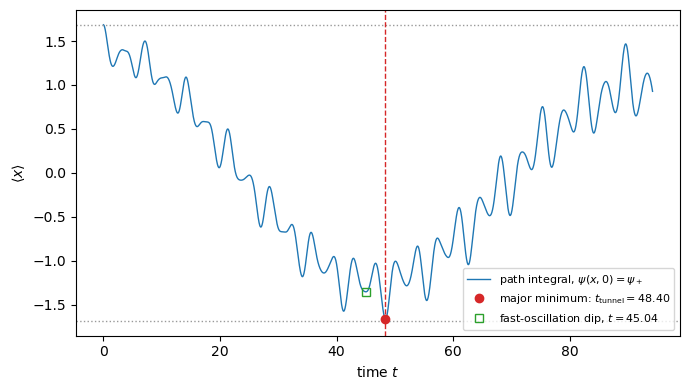

In [4]:
plt.figure(figsize=(7, 4))
plt.plot(t_A, x_mean_A, lw=1, label=r"path integral, $\psi(x,0)=\psi_+$")
plt.axhline(x_min, color="0.6", ls=":", lw=1)
plt.axhline(-x_min, color="0.6", ls=":", lw=1)
plt.axvline(t_tunnel, color="C3", ls="--", lw=1)
plt.plot(t_tunnel, x_tunnel, "o", color="C3",
         label=rf"major minimum: $t_{{\rm tunnel}} = {t_tunnel:.2f}$")
plt.plot(t_A[i_fast], x_mean_A[i_fast], "s", color="C2", mfc="none",
         label=rf"fast-oscillation dip, $t = {t_A[i_fast]:.2f}$")
plt.xlabel("time $t$")
plt.ylabel(r"$\langle x \rangle$")
plt.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("figs/A_mean_x.pdf")
plt.show()

## B

In [5]:
# ===== Problem B(i): 验证 (validation), 和 Banerjee & Bhatnagar Table I 比较 =====
# 他们的 lambda = alpha / 4, 所以 alpha = 0.4, 0.6 对应 lambda = 0.10, 0.15
# Table I 的值 (lecture 10 slides): (E0, E1)
table = {0.4: (1.2345071627860, 1.3469408689225),
         0.6: (1.0624992479565, 1.4210868905393)}

x2, dx2 = make_grid(8, 1200)   # 网格间距减半, 用来判断误差来源
for a, (E0_ref, E1_ref) in table.items():
    E_600, _ = lowest_states(x, dx, a)
    E_1200, _ = lowest_states(x2, dx2, a)
    # 三点差分误差 ~ dx^2, 所以 Richardson 外推 (4 E(dx/2) - E(dx)) / 3 可以消掉主导误差
    E_rich = (4 * E_1200 - E_600) / 3
    print(f"alpha = {a}  (lambda = {a / 4:.2f})")
    for n, ref in enumerate((E0_ref, E1_ref)):
        print(f"  E{n}: table {ref:.10f}  N_D=600 {E_600[n]:.10f} (err {E_600[n] - ref:+.2e})"
              f"  N_D=1200 err {E_1200[n] - ref:+.2e}  Richardson err {E_rich[n] - ref:+.2e}")
    dE_ref = E1_ref - E0_ref
    print(f"  dE: table {dE_ref:.10f}  N_D=600 {E_600[1] - E_600[0]:.10f}"
          f" (err {E_600[1] - E_600[0] - dE_ref:+.2e})")

alpha = 0.4  (lambda = 0.10)
  E0: table 1.2345071628  N_D=600 1.2344772371 (err -2.99e-05)  N_D=1200 err -7.48e-06  Richardson err +3.56e-10
  E1: table 1.3469408689  N_D=600 1.3469042749 (err -3.66e-05)  N_D=1200 err -9.15e-06  Richardson err +3.87e-10
  dE: table 0.1124337061  N_D=600 0.1124270378 (err -6.67e-06)
alpha = 0.6  (lambda = 0.15)
  E0: table 1.0624992480  N_D=600 1.0624798130 (err -1.94e-05)  N_D=1200 err -4.86e-06  Richardson err +2.76e-10
  E1: table 1.4210868905  N_D=600 1.4210435761 (err -4.33e-05)  N_D=1200 err -1.08e-05  Richardson err +2.80e-10
  dE: table 0.3585876426  N_D=600 0.3585637630 (err -2.39e-05)


In [6]:
# ===== Problem B(ii): 在自己的 alpha 下的收敛性 (convergence) =====
# 改网格间距和盒子大小的地方: make_grid(L, n_d) 设定 dx = L / n_d,
# hamiltonian(x, dx) 用新的 dx 和 V(x) 重新生成矩阵
E, phi = lowest_states(x, dx)
E0, E1 = E
dE = E1 - E0
print(f"original grid: E0 = {E0:.8f}, E1 = {E1:.8f}, dE = {dE:.8f}")

grids = (("Original", 8, 600), ("Half spacing", 8, 1200), ("Larger box", 12, 900))
print(f"{'grid':14s}{'L':>4s}{'N_D':>6s}{'E0':>13s}{'E1':>13s}{'dE':>13s}{'change in dE':>15s}")
for name, L, n_d in grids:
    xg, dxg = make_grid(L, n_d)
    Eg, _ = lowest_states(xg, dxg)
    dEg = Eg[1] - Eg[0]
    print(f"{name:14s}{L:4d}{n_d:6d}{Eg[0]:13.8f}{Eg[1]:13.8f}{dEg:13.8f}{dEg - dE:+15.2e}")

original grid: E0 = 1.27424143, E1 = 1.34091986, dE = 0.06667843
grid             L   N_D           E0           E1           dE   change in dE
Original         8   600   1.27424143   1.34091986   0.06667843      +2.22e-16
Half spacing     8  1200   1.27426619   1.34094705   0.06668086      +2.44e-06
Larger box      12   900   1.27424143   1.34091986   0.06667843      -1.04e-10


norms: [1. 1.]


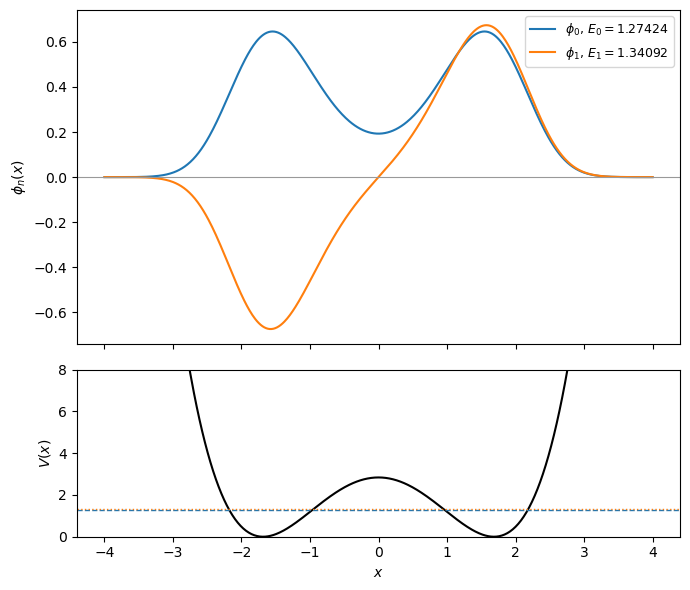

In [7]:
# ===== Problem B(iii): 本征函数 (eigenfunctions) 和势能分两个子图, 共享 x 轴 =====
print("norms:", dx * np.sum(phi**2, axis=0))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(x, phi[:, 0], label=rf"$\phi_0$, $E_0 = {E0:.5f}$")
ax1.plot(x, phi[:, 1], label=rf"$\phi_1$, $E_1 = {E1:.5f}$")
ax1.axhline(0, color="0.6", lw=0.8)
ax1.set_ylabel(r"$\phi_n(x)$")
ax1.legend(fontsize=9)
ax2.plot(x, V(x), "k")
ax2.axhline(E0, color="C0", ls="--", lw=1)
ax2.axhline(E1, color="C1", ls=":", lw=1)
ax2.set_ylim(0, 8)
ax2.set_xlabel("$x$")
ax2.set_ylabel("$V(x)$")
plt.tight_layout()
plt.savefig("figs/B_eigenfunctions.pdf")
plt.show()

## C

In [8]:
# ===== Problem C(i): 用 psi_S, psi_A 估计能量, 题目式 (C) =====
# E_S = <psi_S|H|psi_S> / <psi_S|psi_S>, 分子分母都是 dx * sum; 用 B 的 H 矩阵
# 保留分母: psi_+ 和 psi_- 有一点重叠 (overlap), 所以 psi_S, psi_A 不是归一化的
H = hamiltonian(x, dx)
psi_p, psi_m = psi_well(x, x_min), psi_well(x, -x_min)
psi_S = (psi_p + psi_m) / np.sqrt(2)
psi_Anti = (psi_p - psi_m) / np.sqrt(2)


def energy(psi):
    return (dx * psi @ (H @ psi)) / (dx * psi @ psi)


E_S, E_A = energy(psi_S), energy(psi_Anti)
print(f"overlap <psi_+|psi_-> = {dx * psi_p @ psi_m:.3e}")
print(f"norms: <S|S> = {dx * psi_S @ psi_S:.6f}, <A|A> = {dx * psi_Anti @ psi_Anti:.6f}")
for name, Eh, En in (("E_S vs E0", E_S, E0), ("E_A vs E1", E_A, E1), ("gap", E_A - E_S, dE)):
    print(f"{name:10s}: harmonic {Eh:.6f}  numerical {En:.6f}  "
          f"signed err {Eh - En:+.6f}  rel err {abs(Eh - En) / abs(En):.4f}")

overlap <psi_+|psi_-> = 3.268e-04
norms: <S|S> = 1.000327, <A|A> = 0.999673
E_S vs E0 : harmonic 1.444086  numerical 1.274241  signed err +0.169845  rel err 0.1333
E_A vs E1 : harmonic 1.450345  numerical 1.340920  signed err +0.109425  rel err 0.0816
gap       : harmonic 0.006259  numerical 0.066678  signed err -0.060420  rel err 0.9061


V(0) = 2.8377,  V_+(0) = 4 x_min^2 = 11.3507
at x = 0: |psi_S| = 2.490e-02,  |phi_0| = 1.928e-01,  ratio phi_0/psi_S = 7.7


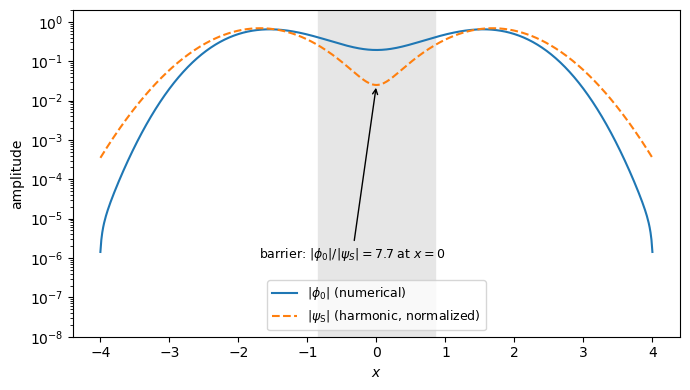

In [9]:
# ===== Problem C(ii): |psi_S| (归一化后) 和 |phi_0| 的对数坐标比较 =====
# 势垒区 (barrier region, x ~ 0): 谐振子近似的势 V_+ 在 x = 0 处是 4 x_min^2 = 4/alpha,
# 远高于真正的势垒 V(0) = 1/alpha, 所以 psi_S 在势垒里衰减得太快
psi_S_n = psi_S / np.sqrt(dx * psi_S @ psi_S)
i0 = N_D // 2   # x[300] = 0
print(f"V(0) = {V(0.0):.4f},  V_+(0) = 4 x_min^2 = {4 * x_min**2:.4f}")
print(f"at x = 0: |psi_S| = {abs(psi_S_n[i0]):.3e},  |phi_0| = {abs(phi[i0, 0]):.3e},"
      f"  ratio phi_0/psi_S = {abs(phi[i0, 0] / psi_S_n[i0]):.1f}")

plt.figure(figsize=(7, 4))
plt.semilogy(x, np.abs(phi[:, 0]), label=r"$|\phi_0|$ (numerical)")
plt.semilogy(x, np.abs(psi_S_n), "--", label=r"$|\psi_{\rm S}|$ (harmonic, normalized)")
plt.annotate(f"barrier: $|\\phi_0|/|\\psi_S| = {abs(phi[i0, 0] / psi_S_n[i0]):.1f}$ at $x=0$",
             xy=(0, abs(psi_S_n[i0])), xytext=(-1.7, 1e-6), fontsize=9,
             arrowprops=dict(arrowstyle="->"))
plt.axvspan(-0.5 * x_min, 0.5 * x_min, color="0.9")
plt.ylim(1e-8, 2)
plt.xlabel("$x$")
plt.ylabel("amplitude")
plt.legend(fontsize=9, loc="lower center")
plt.tight_layout()
plt.savefig("figs/C_log_psi.pdf")
plt.show()

## D

In [10]:
# ===== Problem D: 两种演化方法比较, 初始态 (phi_0 + phi_1)/sqrt(2) (B 的符号) =====
# 一个完整振荡 T = 2 pi / dE, 演化到第一个 >= T 的时间步
T = 2 * np.pi / dE
n_D = int(np.ceil(T / eps))
t_D = np.arange(n_D + 1) * eps
psi0_D = (phi[:, 0] + phi[:, 1]) / np.sqrt(2)

# (i) 本征态展开 (eigenstate expansion): psi(t) = (e^{-i E0 t} phi_0 + e^{-i E1 t} phi_1) / sqrt(2)
# <x>(t) = x01 cos(dE t), x01 = integral phi_0 x phi_1 dx  (推导见 report)
x01 = dx * np.sum(phi[:, 0] * x * phi[:, 1])
psi_eig = (np.exp(-1j * E0 * t_D)[:, None] * phi[:, 0]
           + np.exp(-1j * E1 * t_D)[:, None] * phi[:, 1]) / np.sqrt(2)
x_eig = mean_x(psi_eig, x, dx)
print(f"x01 = {x01:.6f};  max |grid <x> - x01 cos(dE t)| = {np.abs(x_eig - x01 * np.cos(dE * t_D)).max():.1e}")

# results.json: 同样 33 个时刻 (n = 0, 64, ..., 2048), 直接用公式
x_mean_eig = x01 * np.cos(dE * np.arange(0, 2049, 64) * eps)

# (ii) 路径积分: 直接复用 A 的 K_eps 和 evolve
psi_PI = evolve(psi0_D.astype(np.complex128), K_eps, dx, n_D)
x_PI = mean_x(psi_PI, x, dx)

# (iii) 最大差别
diff = np.abs(x_PI - x_eig)
n_max = np.argmax(diff)
print(f"T = {T:.4f}, n_D = {n_D}, t_last = {t_D[-1]:.4f}")
print(f"max |<x>_PI - <x>_eig| = {diff[n_max]:.4f} at t = {t_D[n_max]:.4f}: "
      f"PI {x_PI[n_max]:+.4f}, eig {x_eig[n_max]:+.4f}")
for f in (0.25, 0.5, 0.75, 1.0):
    j = int(round(f * n_D))
    print(f"  t = {t_D[j]:7.3f}: PI {x_PI[j]:+.4f}  eig {x_eig[j]:+.4f}  diff {x_PI[j] - x_eig[j]:+.4f}")
print(f"min of PI curve: t = {t_D[np.argmin(x_PI)]:.4f};  pi/dE = {np.pi / dE:.4f}")

x01 = 1.476965;  max |grid <x> - x01 cos(dE t)| = 2.3e-14


T = 94.2312, n_D = 3840, t_last = 94.2478
max |<x>_PI - <x>_eig| = 0.0595 at t = 94.2478: PI +1.4175, eig +1.4770
  t =  23.562: PI +0.0024  eig -0.0004  diff +0.0028
  t =  47.124: PI -1.4712  eig -1.4770  diff +0.0057
  t =  70.686: PI +0.0061  eig +0.0012  diff +0.0049
  t =  94.248: PI +1.4175  eig +1.4770  diff -0.0595
min of PI curve: t = 47.5411;  pi/dE = 47.1156


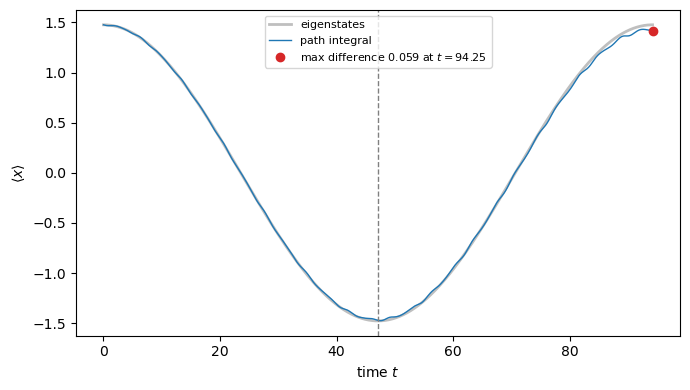

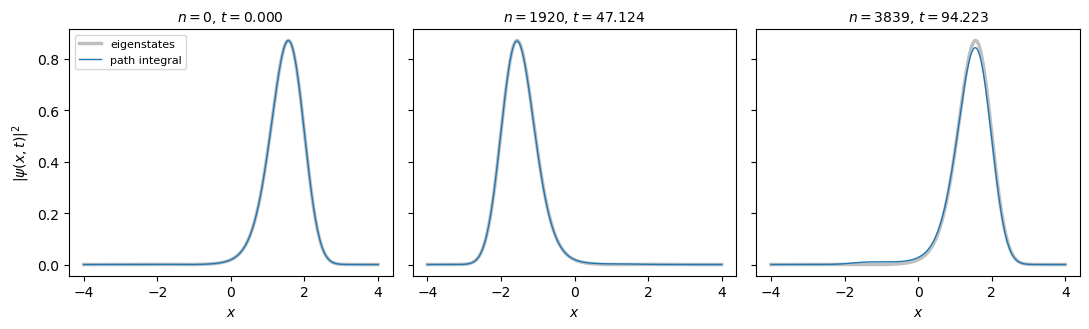

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t_D, x_eig, lw=2, color="0.75", label="eigenstates")
ax.plot(t_D, x_PI, "C0", lw=1, label="path integral")
ax.plot(t_D[n_max], x_PI[n_max], "o", color="C3",
        label=rf"max difference ${diff[n_max]:.3f}$ at $t = {t_D[n_max]:.2f}$")
ax.axvline(np.pi / dE, color="0.5", ls="--", lw=1)
ax.set_xlabel("time $t$")
ax.set_ylabel(r"$\langle x \rangle$")
ax.legend(fontsize=8, loc="upper center")
plt.tight_layout()
plt.savefig("figs/D_mean_x.pdf")
plt.show()

# 概率密度在最接近 0, t_tunnel = pi/dE, T 的时间步
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, t_target in zip(axes, (0.0, np.pi / dE, T)):
    j = int(np.argmin(np.abs(t_D - t_target)))
    ax.plot(x, np.abs(psi_eig[j]) ** 2, lw=2.5, color="0.75", label="eigenstates")
    ax.plot(x, np.abs(psi_PI[j]) ** 2, "C0", lw=1, label="path integral")
    ax.set_title(f"$n = {j}$, $t = {t_D[j]:.3f}$", fontsize=10)
    ax.set_xlabel("$x$")
axes[0].set_ylabel(r"$|\psi(x,t)|^2$")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figs/D_densities.pdf")
plt.show()

In [12]:
# ===== D(iii) 的针对性检查 (targeted check) =====
# 假设: 没归一化的中点传播子 dx * K~ 对 phi_0 型和 phi_1 型的模式衰减因子 |lambda| 稍有不同,
# 每步重新归一化后, phi_0 的权重慢慢变大 -> <x> 的振幅 2 sqrt(w0 w1) x01 变小
# 预测: 权重 |<phi_n|psi_PI>|^2 从 0.5/0.5 漂移, 而 w0 + w1 仍接近 1
w_PI = np.abs(dx * phi.T @ psi_PI.T) ** 2
for j in (0, n_D // 2, n_D):
    print(f"t = {t_D[j]:7.3f}: w0 = {w_PI[0, j]:.4f}, w1 = {w_PI[1, j]:.4f}, "
          f"w0 + w1 = {w_PI[:, j].sum():.4f}, 2 sqrt(w0 w1) x01 = {2 * np.sqrt(w_PI[0, j] * w_PI[1, j]) * x01:.4f}")

t =   0.000: w0 = 0.5000, w1 = 0.5000, w0 + w1 = 1.0000, 2 sqrt(w0 w1) x01 = 1.4770
t =  47.124: w0 = 0.5629, w1 = 0.4367, w0 + w1 = 0.9997, 2 sqrt(w0 w1) x01 = 1.4647
t =  94.248: w0 = 0.6239, w1 = 0.3756, w0 + w1 = 0.9995, 2 sqrt(w0 w1) x01 = 1.4300


## E (bonus)

In [13]:
# ===== Problem E: 对五个 alpha 检验 t_tunnel = pi / dE =====
# 每个 alpha: B 的代码算 dE, A 的代码从 psi_+ 出发演化一个完整慢振荡, 取最深点
# 两态比例 (two-state fraction): |<phi_0|psi_+>|^2 + |<phi_1|psi_+>|^2 (psi_+ 先在网格上归一化)
# 快振荡大小: <x> 减去一个快周期 2 pi/(E2 - E1) 的滑动平均 (moving average) 后的 rms
# 数值误差检查: 在测得的 t_tunnel 处, 演化中的态在 phi_0 + phi_1 上的权重 (和初始比例比较)
alpha_list = [0.30, 0.35, 0.40, 0.45, 0.50]
delta_E_list, t_tunnel_list, frac_list, frac_tun, fast_rms, curves = [], [], [], [], [], []
for a in alpha_list:
    Ea, phia = lowest_states(x, dx, a, k=3)
    dEa = Ea[1] - Ea[0]
    xm_a = 1 / np.sqrt(a)
    pp = psi_well(x, xm_a)
    pp = pp / np.sqrt(dx * pp @ pp)
    n_a = int(np.ceil(2 * np.pi / dEa / eps))
    psi_a = evolve(pp, propagator(x, a), dx, n_a)
    xs = mean_x(psi_a, x, dx)
    ts = np.arange(n_a + 1) * eps
    t_tun, _ = tunnel_time(ts, xs)
    frac_tun.append(np.sum(np.abs(dx * phia[:, :2].T @ psi_a[np.argmin(xs)]) ** 2))
    win = int(round(2 * np.pi / (Ea[2] - Ea[1]) / eps))
    smooth = np.convolve(xs, np.ones(win) / win, mode="same")
    core = slice(win, n_a + 1 - win)
    delta_E_list.append(dEa)
    t_tunnel_list.append(t_tun)
    frac_list.append(np.sum((dx * phia[:, :2].T @ pp) ** 2))
    fast_rms.append(np.sqrt(np.mean((xs - smooth)[core] ** 2)))
    curves.append((ts, xs))
    print(f"alpha = {a:.2f}: dE = {dEa:.6f}, pi/dE = {np.pi / dEa:8.3f}, t_tunnel = {t_tun:8.3f}, "
          f"ratio = {t_tun * dEa / np.pi:.4f}, two-state fraction = {frac_list[-1]:.4f} "
          f"(at t_tunnel: {frac_tun[-1]:.4f}), "
          f"fast rms = {fast_rms[-1]:.3f}, fast period = {2 * np.pi / (Ea[2] - Ea[1]):.2f}")

alpha = 0.30: dE = 0.029872, pi/dE =  105.168, t_tunnel =  100.040, ratio = 0.9512, two-state fraction = 0.9538 (at t_tunnel: 0.6586), fast rms = 0.187, fast period = 3.28


alpha = 0.35: dE = 0.064656, pi/dE =   48.589, t_tunnel =   48.400, ratio = 0.9961, two-state fraction = 0.9420 (at t_tunnel: 0.8632), fast rms = 0.182, fast period = 3.57


alpha = 0.40: dE = 0.112427, pi/dE =   27.943, t_tunnel =   28.152, ratio = 1.0075, two-state fraction = 0.9304 (at t_tunnel: 0.8981), fast rms = 0.170, fast period = 3.78


alpha = 0.45: dE = 0.169294, pi/dE =   18.557, t_tunnel =   17.745, ratio = 0.9562, two-state fraction = 0.9205 (at t_tunnel: 0.9080), fast rms = 0.180, fast period = 3.90


alpha = 0.50: dE = 0.231199, pi/dE =   13.588, t_tunnel =   13.524, ratio = 0.9952, two-state fraction = 0.9131 (at t_tunnel: 0.9076), fast rms = 0.173, fast period = 3.94


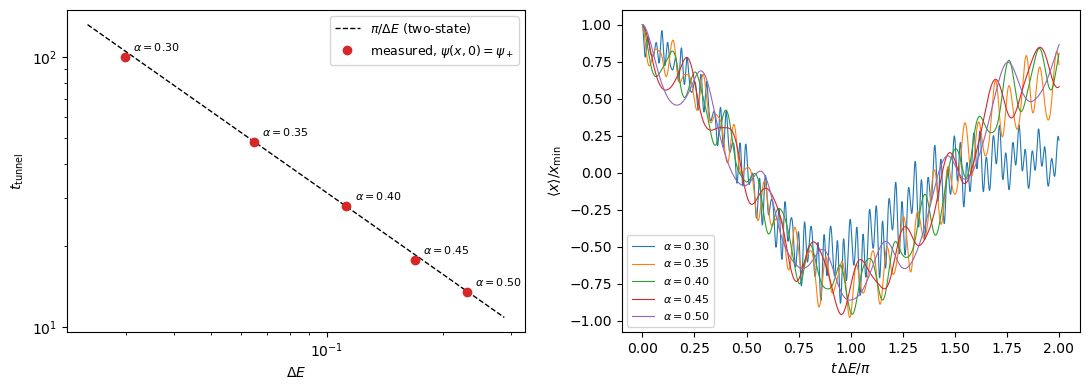

In [14]:
dE_arr = np.array(delta_E_list)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
grid_dE = np.geomspace(dE_arr.min() * 0.8, dE_arr.max() * 1.25, 50)
ax1.loglog(grid_dE, np.pi / grid_dE, "k--", lw=1, label=r"$\pi/\Delta E$ (two-state)")
ax1.loglog(dE_arr, t_tunnel_list, "o", color="C3", label=r"measured, $\psi(x,0)=\psi_+$")
for a, dEa, tt in zip(alpha_list, dE_arr, t_tunnel_list):
    ax1.annotate(rf"$\alpha={a:.2f}$", (dEa, tt), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax1.set_xlabel(r"$\Delta E$")
ax1.set_ylabel(r"$t_{\rm tunnel}$")
ax1.legend(fontsize=9)
for a, dEa, (ts, xs) in zip(alpha_list, dE_arr, curves):
    ax2.plot(ts * dEa / np.pi, xs * np.sqrt(a), lw=0.8, label=rf"$\alpha={a:.2f}$")
ax2.set_xlabel(r"$t\,\Delta E/\pi$")
ax2.set_ylabel(r"$\langle x\rangle / x_{\min}$")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figs/E_tunnel.pdf")
plt.show()

## results.json

In [15]:
results = {
    "tsn": TSN,
    "alpha": alpha,
    "x_mean_pi": x_mean_pi.tolist(),
    "t_tunnel": float(t_tunnel),
    "E0": float(E0), "E1": float(E1),
    "phi0": phi[:, 0].tolist(), "phi1": phi[:, 1].tolist(),
    "E_S": float(E_S), "E_A": float(E_A),
    "x_mean_eig": x_mean_eig.tolist(),
    "delta_E_list": [float(dE) for dE in delta_E_list],
    "t_tunnel_list": [float(t) for t in t_tunnel_list],
}
with open("results.json", "w") as f:
    json.dump(results, f)
print({k: (len(v) if isinstance(v, list) else v) for k, v in results.items()})

{'tsn': '200348262', 'alpha': 0.3524, 'x_mean_pi': 33, 't_tunnel': 48.40016181936775, 'E0': 1.2742414283413754, 'E1': 1.3409198565583027, 'phi0': 601, 'phi1': 601, 'E_S': 1.4440859613472752, 'E_A': 1.4503447744915363, 'x_mean_eig': 33, 'delta_E_list': 5, 't_tunnel_list': 5}
